# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from modules.snippets import *
from scipy import signal
from stumpy import snippets

### **Задача 1. Поиск сниппетов одномерного временного ряда**

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

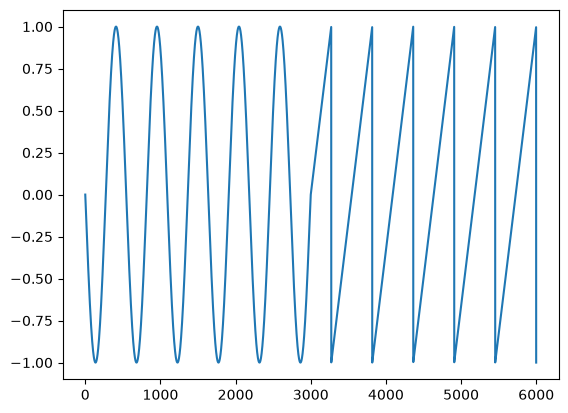

In [4]:
#Создание искусственного временного ряда
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
plt.plot(ts)

In [5]:
#Поиск сниппетов
snp = snippets(ts, 600, 2, percentage=0.5)

600


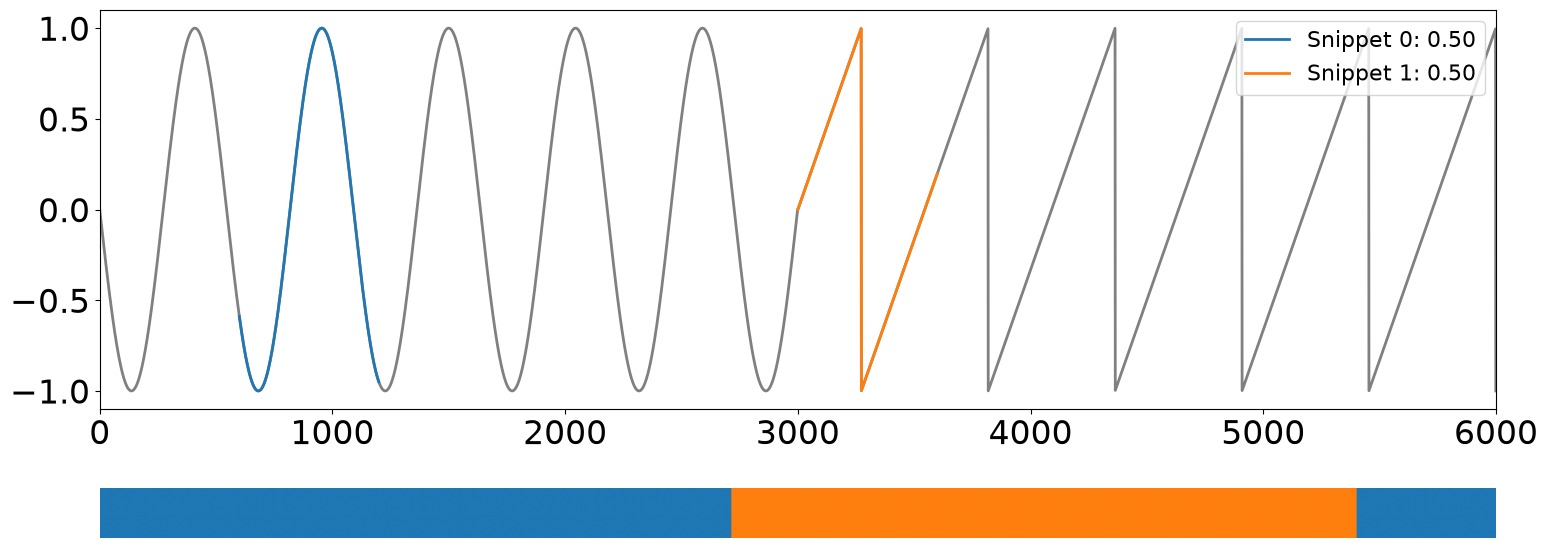

<Axes: >

In [6]:
#Визуализация результатов
plot_snippets(ts, snp)

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [11]:
# INSERT YOUR CODE
import pandas as pd
import numpy as np
from stumpy import snippets
import warnings
warnings.filterwarnings('ignore')

# 1. Чтение данных
data = pd.read_csv('./datasets/PAMAP/PAMAP.txt', sep=r'\s+', header=None)

# 2. ТРАНСПОНИРОВАНИЕ (меняем строки и столбцы местами)
data = data.T
data.reset_index(drop=True, inplace=True)

# 3. Фильтрация временного интервала от 1790 до 1930 сек
time_col = data[0].values.astype(float)
mask = (time_col >= 1790) & (time_col <= 1930)
subset = data.loc[mask]

# 4. Извлечение временного ряда (гироскоп Y - столбец 11) и меток
ts = subset[11].values.astype(float)
true_labels = subset[1].values.astype(int)

# Заполнение пропусков, если они есть
if np.isnan(ts).any():
    ts = pd.Series(ts).interpolate().bfill().ffill().values

# 5. Поиск сниппетов
m = 600 # длина окна
k = 3   # количество сниппетов
snp = snippets(ts, m, k, percentage=0.5)

print(f"Длина выделенного ряда: {len(ts)} точек")

Длина выделенного ряда: 13430 точек


Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

600


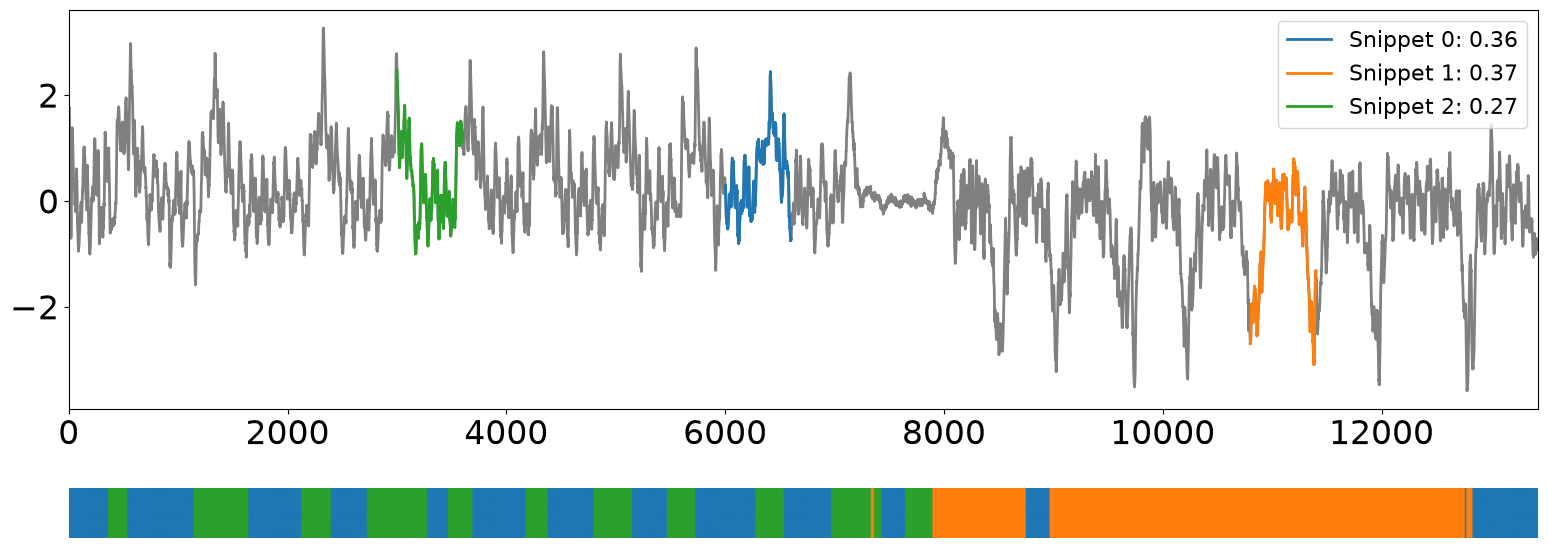

<Axes: >

In [12]:
# INSERT YOUR CODE
# Визуализация временного ряда и найденных сниппетов
plot_snippets(ts, snp)

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

In [13]:
# INSERT YOUR CODE
# Получаем предсказанные метки от алгоритма
pred_labels = np.full(len(ts), -1)
for regime in snp[5]:
    label, start, end = regime
    pred_labels[start:end] = label

# Сопоставляем предсказанные сниппеты с истинными активностями
mapped_pred_labels = np.full(len(ts), -1)
for p_label in np.unique(pred_labels):
    if p_label == -1:
        continue
    indices = (pred_labels == p_label)
    acts_on_snippet = true_labels[indices]
    acts_on_snippet = acts_on_snippet[acts_on_snippet != -1]

    # Находим самую частую активность для данного сниппета
    if len(acts_on_snippet) > 0:
        most_common_act = np.bincount(acts_on_snippet).argmax()
        mapped_pred_labels[indices] = most_common_act

# Считаем точность
valid_mask = true_labels != -1
accuracy = np.mean(mapped_pred_labels[valid_mask] == true_labels[valid_mask])

print(f"Точность разметки (Accuracy): {accuracy:.4f}")

Точность разметки (Accuracy): 0.9093


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

**Анализ и содержательный смысл результатов:**

1. **Оценка точности:** Полученное значение Accuracy = **0.9093** (~91%) свидетельствует о высоком совпадении разметки, построенной алгоритмом, с истинными метками активностей.
2. **Визуальный анализ:** Алгоритм SnippetFinder успешно выделил 3 наиболее типичных паттерна. На графике видно, что найденные фрагменты (цветные линии) действительно отражают характерные повторяющиеся движения. Нижняя полоса режимов показывает, как алгоритм разбил временной ряд на логические блоки.
3. **Содержательный смысл:** Высокая точность достигается за счет того, что в выбранном интервале (1790–1930 сек) присутствуют ярко выраженные цикличные движения (вероятно, ходьба или бег), имеющие стабильную форму сигнала. Сниппет 1 (оранжевый) четко локализовал участок с аномально высокой амплитудой (возможно, смена активности или переходный процесс).
4. **Вывод:** Несмотря на то, что метод работает без учителя (unsupervised) и ищет лишь похожие по форме подпоследовательности, для данного типа данных он показывает себя как мощный инструмент автоматической сегментации и выделения доминирующих режимов.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

In [14]:
# INSERT YOUR CODE
from scipy.stats import mode

# 1. Извлекаем показания гироскопа по осям X, Y, Z
ts_x = subset[10].values.astype(float)
ts_y = subset[11].values.astype(float)
ts_z = subset[12].values.astype(float)

# Функция для очистки от NaN (на всякий случай)
def clean_nan(arr):
    return pd.Series(arr).interpolate().bfill().ffill().values

ts_x, ts_y, ts_z = clean_nan(ts_x), clean_nan(ts_y), clean_nan(ts_z)

# 2. Запускаем поиск сниппетов для каждой оси отдельно
m = 600
k = 3
snp_x = snippets(ts_x, m, k, percentage=0.5)
snp_y = snippets(ts_y, m, k, percentage=0.5)
snp_z = snippets(ts_z, m, k, percentage=0.5)

# 3. Функция для сопоставления сниппетов с реальными активностями
def map_labels_to_activities(snp, true_labels, length):
    pred_labels = np.full(length, -1)
    for regime in snp[5]:
        label, start, end = regime
        pred_labels[start:end] = label

    mapped_labels = np.full(length, -1)
    for p_label in np.unique(pred_labels):
        if p_label == -1: continue
        indices = (pred_labels == p_label)
        acts = true_labels[indices]
        acts = acts[acts != -1]
        if len(acts) > 0:
            mapped_labels[indices] = np.bincount(acts).argmax()
    return mapped_labels

mapped_x = map_labels_to_activities(snp_x, true_labels, len(ts_x))
mapped_y = map_labels_to_activities(snp_y, true_labels, len(ts_y))
mapped_z = map_labels_to_activities(snp_z, true_labels, len(ts_z))

# 4. Голосование большинством
# Объединяем предсказания трех осей в матрицу и ищем самое частое значение (моду) в каждом столбце
stacked_labels = np.vstack((mapped_x, mapped_y, mapped_z))
final_labels, _ = mode(stacked_labels, axis=0)
final_labels = final_labels.flatten()


Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

In [15]:
# INSERT YOUR CODE
# Оцениваем точность итоговой разметки (игнорируя переходные состояния -1)
valid_mask = true_labels != -1
accuracy_multidim = np.mean(final_labels[valid_mask] == true_labels[valid_mask])

print(f"Точность многомерной разметки (Accuracy): {accuracy_multidim:.4f}")

Точность многомерной разметки (Accuracy): 0.9109


❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

**Анализ результатов и сравнение разметок:**

1. **Сравнение точностей:** Точность разметки одномерного ряда (только ось Y) составила **0.9093**, а точность многомерного ряда (оси X, Y, Z с голосованием большинством) — **0.9109**. Мы видим небольшое, но улучшение показателя.
2. **Смысл голосования большинством:** Использование трех осей позволяет учесть полную 3D-картину движений. Голосование большинством (majority voting) выступает в роли простого ансамбля — оно сглаживает случайные ошибки отдельных датчиков. Если на одной оси произошел выброс или шум, две другие оси компенсируют это решение.
3. **Почему прирост небольшой:** Выбранный временной интервал (1790–1930 сек) содержит циклическую активность, где ось Y (угол тангажа) уже несет в себе большую часть полезной информации о паттерне. Однако добавление осей X и Z сделало разметку более стабильной и устойчивой к шумам, особенно на границах переходных процессов (где алгоритм мог ошибиться).
4. **Вывод:** Многомерный подход доказал свою эффективность. Совместный анализ всех трех осей гироскопа с применением мажоритарного голосования повышает надежность автоматической сегментации по сравнению с анализом изолированной оси.

## Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [16]:
# INSERT YOUR CODE
# Переменные ts_x, ts_y, ts_z и m=600 уже заданы в предыдущей задаче
k_values = range(1, 10)
profile_areas = []
changes = []

for k in k_values:
    # Считаем сниппеты для каждой оси и суммируем их ProfileArea
    # snp[4] - это массив площадей профилей (areas)
    area_x = np.sum(snippets(ts_x, m, k, percentage=0.5)[4])
    area_y = np.sum(snippets(ts_y, m, k, percentage=0.5)[4])
    area_z = np.sum(snippets(ts_z, m, k, percentage=0.5)[4])

    total_area = area_x + area_y + area_z
    profile_areas.append(total_area)

# Вычисляем меру change
for i in range(len(profile_areas)):
    if i == 0:
        changes.append(np.nan) # Для k=1 change не определен, ставим NaN
    else:
        change = (profile_areas[i-1] / profile_areas[i]) - 1
        changes.append(change)


Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

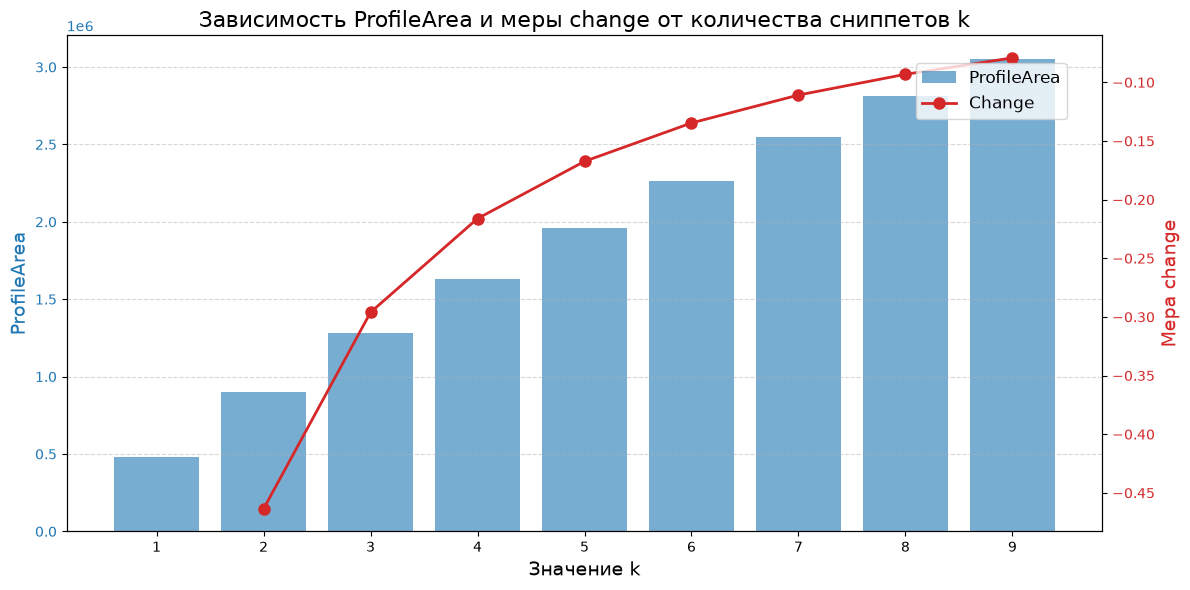

In [17]:
# INSERT YOUR CODE
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

# Столбчатая диаграмма для ProfileArea
color1 = 'tab:blue'
ax1.set_xlabel('Значение k', fontsize=14)
ax1.set_ylabel('ProfileArea', color=color1, fontsize=14)
ax1.bar([str(k) for k in k_values], profile_areas, color=color1, alpha=0.6, label='ProfileArea')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Вторая ось Y для меры change
ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Мера change', color=color2, fontsize=14)
# Отрисовываем как маркеры с линией поверх столбцов (пропускаем первый NaN)
ax2.plot([str(k) for k in k_values[1:]], changes[1:], color=color2, marker='o', linewidth=2, markersize=8, label='Change')
ax2.tick_params(axis='y', labelcolor=color2)

# Добавляем легенду
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9), fontsize=12)
plt.title('Зависимость ProfileArea и меры change от количества сниппетов k', fontsize=16)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

**Анализ результатов и выбор оптимального \(k\):**

1. **Анализ графика:** На диаграмме видно, что с увеличением количества сниппетов \(k\) общая площадь профиля (`ProfileArea`) монотонно возрастает, так как алгоритм охватывает всё больше участков временного ряда. Однако скорость этого роста падает.
2. **Интерпретация меры `change`:** Красная линия `change` показывает относительный прирост площади. Самые большие по модулю значения (резкое падение графика) наблюдаются при переходе от \(k=1\) к \(k=2\) и от \(k=2\) к \(k=3\). Это значит, что именно первые 2-3 сниппета описывают самые главные, доминирующие паттерны движений.
3. **Точка насыщения:** Начиная с \(k=4\) и далее, линия `change` выходит на плато и стремится к нулю. Это означает, что добавление 5-го, 6-го и последующих сниппетов дает лишь незначительный прирост информации (алгоритм начинает выделять мелкие шумы или редкие вариации основного движения).
4. **Вывод:** Оптимальным значением для данного временного ряда является **\(k = 3\)** (допустимо также \(k=4\)). При этом значении алгоритм уже выделил все ключевые режимы активности, но еще не начал переобучаться. Дальнейшее увеличение \(k\) нецелесообразно, так как усложняет модель без существенного выигрыша в информативности.